In [26]:
import matplotlib.pyplot as plt
import sys
sys.path.append('../')
from utils import plotting_utils
import pickle
import jax.numpy as jnp
import pickle as pkl
import interpax as ipx
from datetime import datetime, timedelta


In [27]:
parameterization = "permaFoam_omega10" # permaFoam_omega50, drying, drying_omega10, cap

# input_folder =  "../input/era5_land_data/Sweden/"
# input_filename = "sim_2312_2405.pkl"
# input_filename = "spinup_2308_2311.pkl"
input_folder = None
input_filename = None

# sim_folder = "../output/Simulations_Paper/ERA5_Sweden/simulations/"
# sim_filename = f"simulation_{parameterization}.pkl"

sim_folder = "../output/Simulations_Paper/Constant/"
sim_filename = f"{parameterization}.pkl"

# save_folder = "../figures/Simulations_Paper/ERA5_Sweden/Winter2024/" 
# save_filename = f"simulation_{parameterization}"

save_folder = "../figures/Simulations_Paper/Constant/"
save_filename = f"{parameterization}"

In [28]:
# with open(f"../output/Simulations_Paper/ERA5_Sweden/simulations/simulation_{parameterization}.pkl", 'rb') as pickle_file:
# with open(f"../output/Simulations_Paper/ERA5_Sweden/spinup/spinup_{parameterization}.pkl", 'rb') as pickle_file:
with open(sim_folder+sim_filename, 'rb') as pickle_file:
    db = pickle.load(pickle_file)

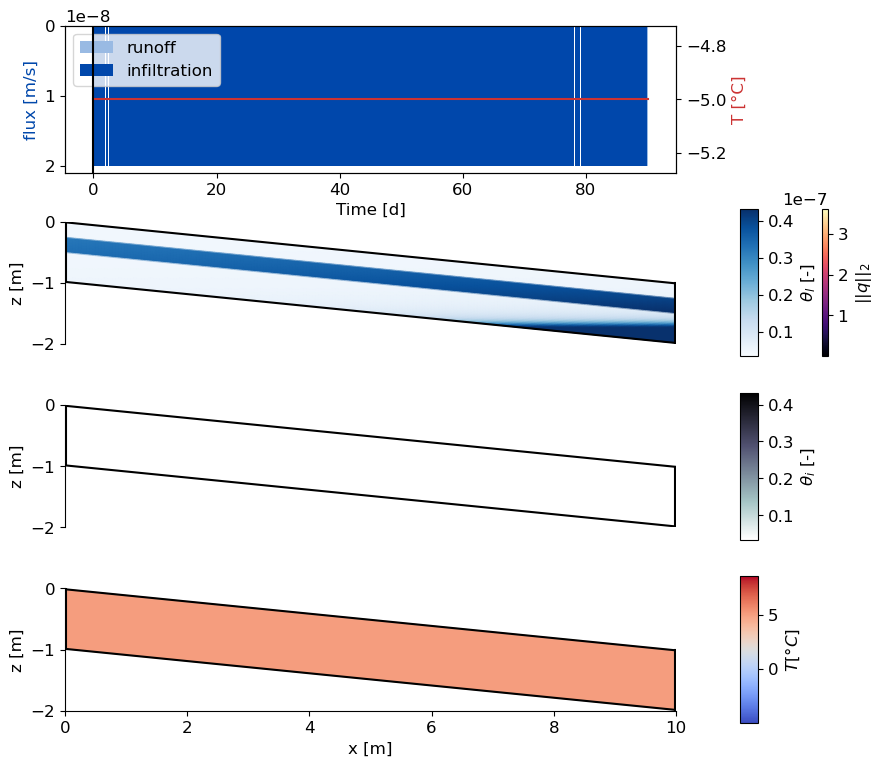

In [29]:
if input_folder is not None and input_filename is not None:
    with open(input_folder + input_filename, "rb") as f:
        db_input = pkl.load(f)
        dates = [db_input["dates"][0] + timedelta(seconds=float(t)) for t in db['time_array']]
        t_bc = db_input["time"]
        t_bc = t_bc - t_bc[0]
        T_surface = db_input["skt"]
        q_inf = db_input["recharge"]
        T_surface_interp = ipx.Interpolator1D(t_bc, T_surface,method="cubic2")
        recharge_interp = ipx.Interpolator1D(t_bc, q_inf,method="cubic2")

        recharge = recharge_interp(db['time_array'])
        T_surface = T_surface_interp(db['time_array'])
        q_runoff = jnp.sum(jnp.array(db["q_runoff"]),axis=1)/jnp.array(db["q_runoff"]).shape[1]
        q_inf = recharge - q_runoff
        print(jnp.shape(recharge), jnp.shape(T_surface), jnp.shape(q_inf),jnp.shape(db['time_array']), len(dates))

        ani, fig, ax = plotting_utils.create_animation_streamlines(db['X'], db['Z'], db['theta_l_total'], db['qx_centered_array'], db['qz_centered_array'],  db['theta_i_total'],  db['T_total'],recharge,q_inf, T_surface, jnp.array(db['time_array']), dates, slope=-0.1, time_mode="date", density=1, linewidth = 4, cmaps=('Blues', 'bone_r','coolwarm'), clabels=(r'$\theta_l$ [-]', r'$\theta_i$ [-]',r'$T[°C]$'),cmap_stream="magma",arrowsize=0)

else: 
    time = jnp.array(db["time_array"])
    recharge = 2e-8*jnp.ones_like(time)
    T_surface = -5*jnp.ones_like(time)

    q_runoff = jnp.sum(jnp.array(db["q_runoff"]),axis=1)/jnp.array(db["q_runoff"]).shape[1]
    q_inf = recharge - q_runoff
    ani, fig, ax = plotting_utils.create_animation_streamlines(db['X'], db['Z'], db['theta_l_total'], db['qx_centered_array'], db['qz_centered_array'],  db['theta_i_total'],  db['T_total'],recharge,q_inf, T_surface, time, slope=-0.1, density=1, linewidth = 4, cmaps=('Blues', 'bone_r','coolwarm'), clabels=(r'$\theta_l$ [-]', r'$\theta_i$ [-]',r'$T[°C]$'),cmap_stream="magma",arrowsize=0)

In [30]:
ani.save(save_folder+save_filename+'.mp4', writer='ffmpeg', fps=5)

/home/anne/anaconda3/envs/frozen_CPU/lib/python3.14/site-packages/matplotlib/patches.py:3436: RuntimeWarning: invalid value encountered in scalar divide
  cos_t, sin_t = head_length / head_dist, head_width / head_dist
